In [1]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate
from langchain_openai import ChatOpenAI

# Setting LLM 
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.9, max_tokens=1000)

# Create a prompt template for generating DALL-E image prompts
prompt = PromptTemplate.from_template(
    "Generate a detailed IMAGE GENERATION prompt for DALL-E based on the following description. "
    "Return only the prompt, no intro, no explanation, no chatty, no markdown, no code block, no nothing. Just the prompt"
    "Output should be less than 200 characters. Write in English only."
    "Image Description: \n{image_desc}",
)

# Create a chain by combining the prompt template and LLM with an output parser 
chain = prompt | llm | StrOutputParser()

# Run the chain with a specific image description
image_prompt = chain.invoke(
    {"image_desc": "로봇과 함께 생활하는 미래를 풍자한 neo-classicism painting"}
)

# Output the generated image prompt
print(image_prompt)

A neo-classical painting depicting a humorous future where humans coexist with robots, showcasing vibrant colors and intricate details, blending classical elements with futuristic technology.


In [ ]:
from langchain_community.utilities.dalle_image_generator import DallEAPIWrapper
from IPython.display import Image

# Initialize DALL-E API Wrapper  // 이건 이제 이 모델 사용X
dalle = DallEAPIWrapper(model="dall-e-3", size="1024x1024", quality="standard", n=1)

# Define the image description query
query = "로봇과 함께 생활하는 미래를 풍자한 neo-classicism painting"

# Generate the image using the DALL-E API
image_url = dalle.run(chain.invoke({"image_desc": query}))

# Display the generated image
Image(url=image_url, width=300)


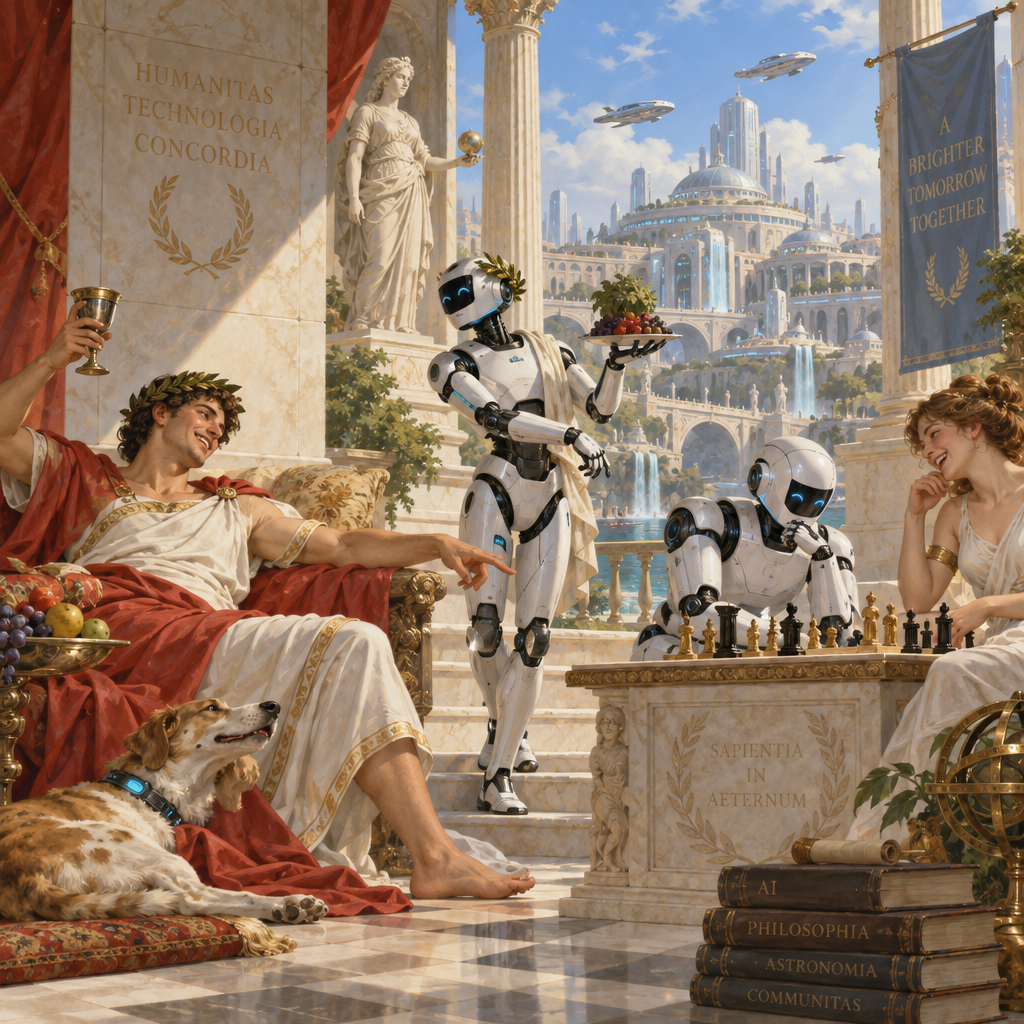

In [4]:
from openai import OpenAI
from IPython.display import Image, display
import base64

client = OpenAI()

# 이미지 설명
query = "로봇과 함께 생활하는 미래를 풍자한 neo-classicism painting"

# 기존 LangChain 체인으로 프롬프트 생성
prompt = chain.invoke({"image_desc": query})

# GPT Image 모델로 이미지 생성
response = client.images.generate(
    model="gpt-image-2.5-sunburst",
    prompt=prompt,
    size="1024x1024"
)

# 이미지 데이터 디코딩
image_data = base64.b64decode(response.data[0].b64_json)

# 이미지 출력
display(Image(data=image_data, width=300))